## Understanding the Dataset

In [4]:
%pip install scikit-learn pandas numpy matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 29.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 35.7 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 34.6 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 35.1 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 35.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 26.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 37.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 35.4 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15/15 [matplotlib]5 [matplotlib]n]
Note: you may need to restart the kernel to use updated packages.


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
df=pd.read_csv("data/train_aiproject.csv")
df

,Timestamp,Signal Strength (dBm),SNR,Call Duration (s),Environment,Attenuation,Distance to Tower (km),Tower ID,User ID,Call Type,Incoming/Outgoing
0,2022-01-03 17:46:13,-84.119763,25.940082,1713.800550,urban,14.690438,2.243176,5,25,data,incoming
1,2022-01-04 17:29:31,-87.806131,15.937354,345.371848,home,6.213698,5.002566,3,22,voice,incoming
2,2022-01-05 17:14:01,-116.575176,14.709384,259.285043,open,4.494415,8.705974,2,5,voice,incoming
3,2022-01-06 16:02:29,-82.961183,21.727165,357.974004,home,7.619957,7.427025,5,33,data,outgoing
4,2022-01-07 22:19:17,-85.012574,26.058158,398.006716,urban,10.655159,0.612071,5,8,voice,outgoing
...,...,...,...,...,...,...,...,...,...,...,...
458,2022-04-05 10:16:11,-77.606140,26.519150,327.551183,suburban,4.005920,8.101746,9,27,data,outgoing
459,2022-04-06 14:43:53,-110.548728,15.147635,1503.636459,open,2.652199,7.719386,5,31,voice,outgoing
460,2022-04-07 17:08:49,-108.254563,20.451654,1761.584061,open,2.071428,2.492435,10,47,data,incoming
461,2022-04-08 16:01:41,-99.218386,12.254734,355.301551,open,3.378450,9.268362,3,20,voice,outgoing


In [9]:
print("Dimensions of dataset:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())   
print("\nFirst five rows:")
display(df.head())
print("\nData types and missing-value overview:")
display(df.info())
print("\nSummary of numeric columns:")
display(df.describe())

Dimensions of dataset: (463, 11)

Column names:
['Timestamp', 'Signal Strength (dBm)', 'SNR', 'Call Duration (s)', 'Environment', 'Attenuation', 'Distance to Tower (km)', 'Tower ID', 'User ID', 'Call Type', 'Incoming/Outgoing']

First five rows:


,Timestamp,Signal Strength (dBm),SNR,Call Duration (s),Environment,Attenuation,Distance to Tower (km),Tower ID,User ID,Call Type,Incoming/Outgoing
0,2022-01-03 17:46:13,-84.119763,25.940082,1713.800550,urban,14.690438,2.243176,5,25,data,incoming
1,2022-01-04 17:29:31,-87.806131,15.937354,345.371848,home,6.213698,5.002566,3,22,voice,incoming
2,2022-01-05 17:14:01,-116.575176,14.709384,259.285043,open,4.494415,8.705974,2,5,voice,incoming
3,2022-01-06 16:02:29,-82.961183,21.727165,357.974004,home,7.619957,7.427025,5,33,data,outgoing
4,2022-01-07 22:19:17,-85.012574,26.058158,398.006716,urban,10.655159,0.612071,5,8,voice,outgoing



Data types and missing-value overview:
<class 'pandas.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Timestamp               463 non-null    str    
 1   Signal Strength (dBm)   463 non-null    float64
 2   SNR                     463 non-null    float64
 3   Call Duration (s)       463 non-null    float64
 4   Environment             463 non-null    str    
 5   Attenuation             463 non-null    float64
 6   Distance to Tower (km)  463 non-null    float64
 7   Tower ID                463 non-null    int64  
 8   User ID                 463 non-null    int64  
 9   Call Type               463 non-null    str    
 10  Incoming/Outgoing       463 non-null    str    
dtypes: float64(5), int64(2), str(4)
memory usage: 39.9 KB


None


Summary of numeric columns:


,Signal Strength (dBm),SNR,Call Duration (s),Attenuation,Distance to Tower (km),Tower ID,User ID
count,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000,463.000000
mean,-84.957137,19.834262,895.324971,5.459605,5.064669,5.531317,52.198704
std,14.349536,5.579039,529.838188,3.502259,2.956370,2.837327,27.969438
min,-118.681318,10.271411,11.520904,0.042255,0.026375,1.000000,1.000000
25%,-95.936519,14.857527,418.499303,2.815069,2.509455,3.000000,29.000000
50%,-84.230276,19.584328,910.509884,4.758147,5.183831,6.000000,54.000000
75%,-74.430044,24.648712,1362.754612,7.573055,7.708894,8.000000,75.500000
max,-50.122222,29.963213,1795.175137,14.939793,9.981806,10.000000,100.000000


In [10]:
df=df.drop_duplicates().copy()
target_column="Signal Strength (dBm)"
feature_columns=["SNR","Attenuation","Distance to Tower (km)","Environment"]
missing_columns=[
    col for col in feature_columns+[target_column]
    if col not in df.columns
]
if missing_columns:
    print("Error: These columns do not exist:", missing_columns)
else:
    print("Target:", target_column)
    print("Features:", feature_columns)
    display(df[[target_column] + feature_columns].head())

Target: Signal Strength (dBm)
Features: ['SNR', 'Attenuation', 'Distance to Tower (km)', 'Environment']


,Signal Strength (dBm),SNR,Attenuation,Distance to Tower (km),Environment
0,-84.119763,25.940082,14.690438,2.243176,urban
1,-87.806131,15.937354,6.213698,5.002566,home
2,-116.575176,14.709384,4.494415,8.705974,open
3,-82.961183,21.727165,7.619957,7.427025,home
4,-85.012574,26.058158,10.655159,0.612071,urban


In [11]:
df.to_csv("data/cleaned_data.csv",index=False)

In [12]:

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
model = df[feature_columns + [target_column]].copy()
model[target_column] = pd.to_numeric(model[target_column], errors="coerce")
model= model.dropna(subset=[target_column])
X = model[feature_columns]
y = model[target_column]
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))])

# Fill missing categories with the most frequent category, then encode them
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])

# Apply the appropriate preprocessing to each column type
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)])

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Rows available for modelling:", len(model))

Input shape: (463, 4)
Target shape: (463,)
Numeric features: ['SNR', 'Attenuation', 'Distance to Tower (km)']
Categorical features: ['Environment']
Rows available for modelling: 463


## Model Training

In [13]:

x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("Number of Training examples:", len(x_train))
print("Number of Testing examples:", len(x_test))

Number of Training examples: 370
Number of Testing examples: 93


In [14]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(x_train, y_train)

print("Model training is complete!")

Model training is complete!


## Model Testing


In [15]:
y_pred = model.predict(x_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [16]:
results = pd.DataFrame({
    "Actual Signal Strength": np.array(y_test).flatten(),
    "Predicted Signal Strength": y_pred,
    "Error (Actual - Predicted)": y_test.to_numpy() - y_pred
})

display(results.head(10))

,Actual Signal Strength,Predicted Signal Strength,Error (Actual - Predicted)
0,-82.060041,-83.162773,1.102732
1,-75.037626,-85.846010,10.808384
2,-88.904164,-77.752349,-11.151815
3,-90.745061,-83.714138,-7.030923
4,-66.710577,-84.485327,17.774750
5,-87.866356,-84.924503,-2.941854
6,-91.892598,-88.892639,-2.999960
7,-79.249967,-87.407585,8.157618
8,-66.972822,-79.912457,12.939635
9,-104.138485,-85.721608,-18.416878


In [17]:
print("Number of test samples:", len(x_test))
print("Number of predictions:", len(y_pred))

Number of test samples: 93
Number of predictions: 93


In [22]:
timestamp = "2022-05-15 14:30:00"
snr = 20.5
call_duration = 500
environment = "urban"
attenuation = 8.5
distance_to_tower = 3.5
tower_id = 5
user_id = 25
call_type = "voice"
incoming_outgoing = "incoming"

new_record = pd.DataFrame({
    "Timestamp": [timestamp],
    "SNR": [snr],
    "Call Duration (s)": [call_duration],
    "Environment": [environment],
    "Attenuation": [attenuation],
    "Distance to Tower (km)": [distance_to_tower],
    "Tower ID": [tower_id],
    "User ID": [user_id],
    "Call Type": [call_type],
    "Incoming/Outgoing": [incoming_outgoing]
})

predicted_signal = model.predict(new_record)

print("Predicted Signal Strength (dBm):", predicted_signal[0])

Predicted Signal Strength (dBm): -89.97008658464593


In [18]:
results.to_csv("testing_results.csv", index=False)

print("Testing results saved successfully!")

Testing results saved successfully!


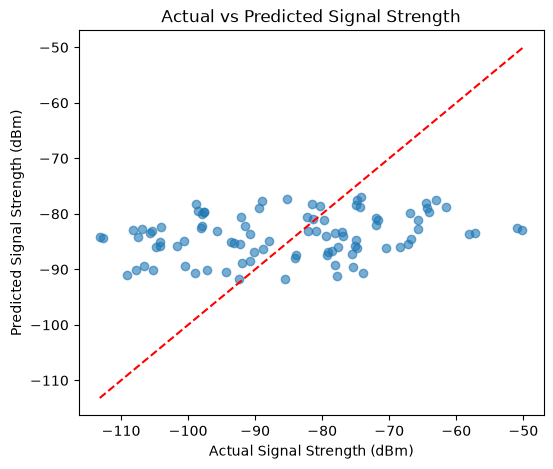

In [19]:
import matplotlib.pyplot as plt 

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Signal Strength (dBm)")
plt.ylabel("Predicted Signal Strength (dBm)")
plt.title("Actual vs Predicted Signal Strength")
plt.savefig("actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

## Error Analysis

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

error_metrics = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Value': [mae, mse, rmse, r2]
})

display(error_metrics)

results = pd.DataFrame({
    'Actual Signal Strength': np.array(y_test).flatten(),
    'Predicted Signal Strength': np.array(y_pred).flatten(),
    'Error (Actual - Predicted)': np.array(y_test).flatten() - np.array(y_pred).flatten()
})

display(results.head(10))

,Metric,Value
0,MAE,12.297309
1,MSE,210.444819
2,RMSE,14.506716
3,R2 Score,0.067065


,Actual Signal Strength,Predicted Signal Strength,Error (Actual - Predicted)
0,-82.060041,-83.162773,1.102732
1,-75.037626,-85.846010,10.808384
2,-88.904164,-77.752349,-11.151815
3,-90.745061,-83.714138,-7.030923
4,-66.710577,-84.485327,17.774750
5,-87.866356,-84.924503,-2.941854
6,-91.892598,-88.892639,-2.999960
7,-79.249967,-87.407585,8.157618
8,-66.972822,-79.912457,12.939635
9,-104.138485,-85.721608,-18.416878
